In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from xgboost import XGBRegressor

In [2]:
df = pd.read_csv("gold XAU_1d_data.csv", sep=";")
df.head()
print(df.shape)

(5516, 6)


In [3]:
df["Date"] = pd.to_datetime(df["Date"])

In [4]:
print("Number of rows:", len(df))
print("Number of columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDate range:")
print(df["Date"].iloc[0], "→", df["Date"].iloc[-1])

Number of rows: 5516
Number of columns: 6

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']

Data types:
Date      datetime64[us]
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object

Date range:
2004-06-11 00:00:00 → 2025-12-31 00:00:00


In [5]:
df = df.sort_values("Date").reset_index(drop=True)

df.head()

,Date,Open,High,Low,Close,Volume
0,2004-06-11,384.0,384.8,382.8,384.1,272
1,2004-06-14,384.3,385.8,381.8,382.8,1902
2,2004-06-15,382.8,388.8,381.1,388.6,1951
3,2004-06-16,387.1,389.8,382.6,383.8,2014
4,2004-06-17,383.6,389.3,383.0,387.6,1568


In [6]:
print(df.dtypes)
print(df.isnull().sum())
print(df[df.duplicated()])

Date      datetime64[us]
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Empty DataFrame
Columns: [Date, Open, High, Low, Close, Volume]
Index: []


In [7]:
# Statistical summary
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,5516,2015-03-20 02:55:57.215373,2004-06-11 00:00:00,2009-11-10 18:00:00,2015-03-25 12:00:00,2020-07-28 06:00:00,2025-12-31 00:00:00,NaN
Open,5516.0,1405.246032,382.8,1063.335,1299.545,1744.1075,4538.0,651.08376
High,5516.0,1415.762846,384.8,1071.165,1307.06,1755.1825,4550.16,656.464934
Low,5516.0,1394.6201,381.1,1053.015,1291.715,1728.5275,4483.01,646.052608
Close,5516.0,1405.606541,382.8,1062.4,1299.92,1743.5325,4531.17,651.689418
Volume,5516.0,85015.067078,2.0,26474.0,72708.0,112226.75,1401078.0,102380.514443


Checking for OHLC Consistency and zero/negative values

In [8]:
ohlc_errors = {
    "High < Open": (df["High"] < df["Open"]).sum(),
    "High < Close": (df["High"] < df["Close"]).sum(),
    "Low > Open": (df["Low"] > df["Open"]).sum(),
    "Low > Close": (df["Low"] > df["Close"]).sum(),
}

pd.Series(ohlc_errors)

High < Open     0
High < Close    0
Low > Open      0
Low > Close     0
dtype: int64

In [9]:
price_columns = ["Open", "High", "Low", "Close"]

print("Negative/zero price values:")
print((df[price_columns] <= 0).sum())

print("\nZero volume values:")
print((df["Volume"] == 0).sum())

Negative/zero price values:
Open     0
High     0
Low      0
Close    0
dtype: int64

Zero volume values:
0


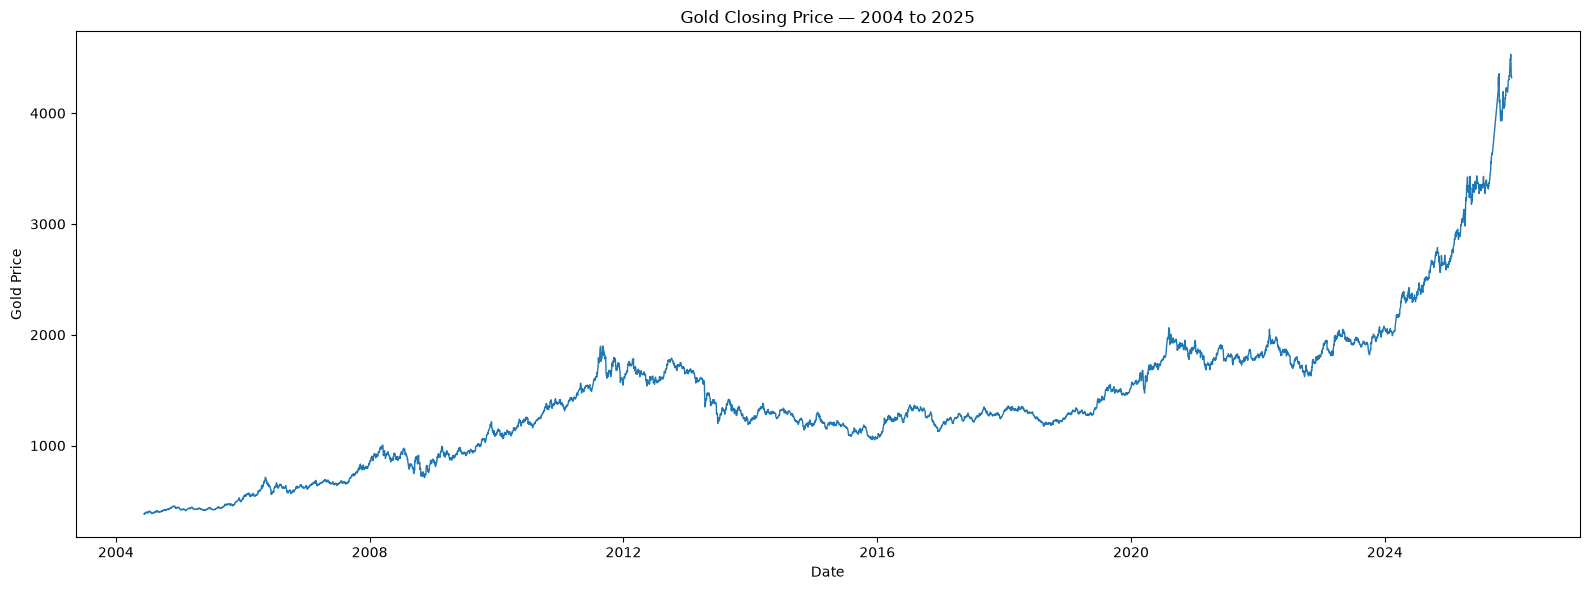

In [10]:
plt.figure(figsize=(16, 6))

plt.plot(
    df["Date"],
    df["Close"],
    linewidth=1
)

plt.title("Gold Closing Price — 2004 to 2025")
plt.xlabel("Date")
plt.ylabel("Gold Price")
plt.tight_layout()

plt.show()

In [ ]:
# Percentage of 
df["Daily_Return"] = df["Close"].pct_change()

df[["Date", "Close", "Daily_Return"]].head(10)

,Date,Close,Daily_Return
0,2004-06-11,384.1,NaN
1,2004-06-14,382.8,-0.003385
2,2004-06-15,388.6,0.015152
3,2004-06-16,383.8,-0.012352
4,2004-06-17,387.6,0.009901
5,2004-06-18,394.3,0.017286
6,2004-06-21,393.1,-0.003043
7,2004-06-22,394.1,0.002544
8,2004-06-23,395.6,0.003806
9,2004-06-24,401.1,0.013903
